Loan Dataset Accuracy: 100.0%
Weight updates per epoch (first 10): [14, 7, 4, 2, 0, 0, 0, 0, 0, 0]
XOR Dataset Accuracy (single perceptron): 50.0% (updates/epoch: [3, 3, 4, 4, 4, 4, 4, 4])


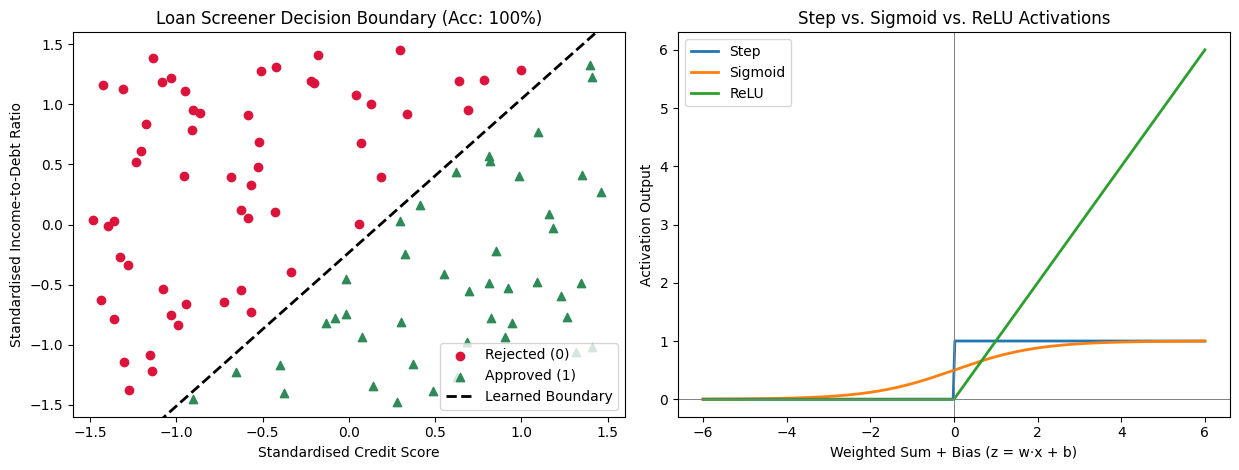

In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

class Perceptron:
    def __init__(self, n_features, lr=0.1, epochs=30):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.updates_per_epoch = []

    @staticmethod
    def step(z):
        return np.where(z >= 0.0, 1, 0)

    def predict(self, X):
        z = X @ self.w + self.b
        return self.step(z)

    def fit(self, X, y):
        self.updates_per_epoch = []
        for _ in range(self.epochs):
            updates = 0
            for xi, yi in zip(X, y):
                pred = self.step(np.dot(xi, self.w) + self.b)
                err = yi - pred
                if err != 0:
                    self.w += self.lr * err * xi
                    self.b += self.lr * err
                    updates += 1
            self.updates_per_epoch.append(updates)
        return self

# 1. Generate 100 loan applications: [credit_score_norm, income_to_debt_norm]
n_loans = 100
credit_norm = np.random.uniform(-1.5, 1.5, n_loans)
itd_norm = np.random.uniform(-1.5, 1.5, n_loans)
X_loan = np.column_stack([credit_norm, itd_norm])

# Linearly separable approval rule: high credit score & lower debt burden
score_rule = 1.4 * credit_norm - 1.1 * itd_norm - 0.2
y_loan = (score_rule >= 0).astype(int)

p_loan = Perceptron(n_features=2, lr=0.1, epochs=25).fit(X_loan, y_loan)
acc_loan = np.mean(p_loan.predict(X_loan) == y_loan)
print(f"Loan Dataset Accuracy: {acc_loan*100:.1f}%")
print("Weight updates per epoch (first 10):", p_loan.updates_per_epoch[:10])

# 2. Train on XOR dataset to show non-convergence
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

p_xor = Perceptron(n_features=2, lr=0.1, epochs=30).fit(X_xor, y_xor)
acc_xor = np.mean(p_xor.predict(X_xor) == y_xor)
print(f"XOR Dataset Accuracy (single perceptron): {acc_xor*100:.1f}% (updates/epoch: {p_xor.updates_per_epoch[:8]})")

# 3. Compare Step, Sigmoid, and ReLU outputs for the same linear inputs z
z_vals = np.linspace(-6, 6, 300)
out_step = np.where(z_vals >= 0, 1.0, 0.0)
out_sigmoid = 1.0 / (1.0 + np.exp(-z_vals))
out_relu = np.maximum(0.0, z_vals)

# Plot Decision Boundary (Loan) & Activation Comparison
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

axes[0].scatter(X_loan[y_loan == 0, 0], X_loan[y_loan == 0, 1], c="crimson", marker="o", label="Rejected (0)")
axes[0].scatter(X_loan[y_loan == 1, 0], X_loan[y_loan == 1, 1], c="seagreen", marker="^", label="Approved (1)")

if abs(p_loan.w[1]) > 1e-6:
    x_line = np.linspace(-1.6, 1.6, 100)
    y_line = -(p_loan.w[0] * x_line + p_loan.b) / p_loan.w[1]
    axes[0].plot(x_line, y_line, "k--", lw=2, label="Learned Boundary")

axes[0].set_xlim(-1.6, 1.6)
axes[0].set_ylim(-1.6, 1.6)
axes[0].set_xlabel("Standardised Credit Score")
axes[0].set_ylabel("Standardised Income-to-Debt Ratio")
axes[0].set_title(f"Loan Screener Decision Boundary (Acc: {acc_loan*100:.0f}%)")
axes[0].legend()

axes[1].plot(z_vals, out_step, lw=2, label="Step")
axes[1].plot(z_vals, out_sigmoid, lw=2, label="Sigmoid")
axes[1].plot(z_vals, out_relu, lw=2, label="ReLU")
axes[1].axhline(0, color="gray", lw=0.7)
axes[1].axvline(0, color="gray", lw=0.7)
axes[1].set_xlabel("Weighted Sum + Bias (z = w·x + b)")
axes[1].set_ylabel("Activation Output")
axes[1].set_title("Step vs. Sigmoid vs. ReLU Activations")
axes[1].legend()

plt.tight_layout()
plt.savefig("exp07_perceptron_activations.png", dpi=150, bbox_inches="tight")
plt.show()